# Modulación LoRa (FSCM)

Modelo en Python de la modulación LoRa basado en el análisis de
L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960),
*IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |


### Que es la modulacion LoRa? 
La modulación LoRa es una técnica de transmisión inalámbrica de radiofrecuencia diseñada específicamente para IoT. Su objetivo principal es enviar pequeñas cantidades de datos a distancias muy largas consumiendo muy poca energía, cambiando velocidad por alcance logrando que el receptor decodifique señales con menos potencia relativa respecto del ruido a costa de transimitir mas lento. Además, existe LoRaWAN que es el protocolo de red construido sobre LoRa.

Algunas de sus principales áreas de aplicación son:

**Agroindustria y Ganadería:**

    Es uno de los sectores donde más éxito tiene por la falta de conectividad en zonas rurales y las enormes distancias.

**Telecomunicaciones Satelitales:**

    Al no haber obstáculos físicos, la altísima sensibilidad de recepción de LoRa permite que una señal de apenas unos pocos milivatios llegue hasta el espacio.

## Modelo del sistema

*ToDo(b-Tomas): diagrama de bloques*

In [15]:
import numpy as np

from lora import LoRaParams, channel, detection, metrics, plots, rng, rx, seed, simulation, tx

# Semilla global: las ejecuciones siempre utilizan los mismos valores aleatorios.
seed(0)


## Transmisión

El módulo transmisor se compone de dos partes:

### Codificador

Para conformar la onda, los datos a transmitir tienen que ser convertidos al alfabeto que el conformador de onda sabe transmitir. Por lo tanto los datos se deben agrupar en vectores de bits $\bold{w}(nT_s)$ con longitud $SF$ y cada vector se convierte en el numero entero que lo representa. Asi, la Ec. 1 transforma vectores de $\bold{w}$ en simbolos $s(nT_s)$, donde para cada periodo de tiempo $(nT_s, (n+1) T_s)$, se conforma la onda correspodiente a un simbolo distinto. 

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

### Conformador de onda

Dada la secuencia de simbolos de $s$, el conformador de onda modula la señal a transmitir de acuerdo a Ec. 2.

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[(s(nT_s) + k) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de _chips_, donde cada grupo de $2^{SF}$ _chips_ forma un _chirp_, representando a un simbolo. Los _chips_ forman la señal discreta a transmitir.

#### Análisis de la señal modulada

<!-- TODO(b-Tomas): Consultar con Ayarde si podemos corregir permanentemente la modulación para el notebook entero. Una vez decidido, conslidar toda esta sección -->
<!-- TODO(b-Tomas): Verificar si estamos dando una definición de chirp acá. Si no, agregarla, porque la seiguiente sección la necesita -->

Antes de continuar con la transmisión, se analiza la forma y comportamiento de la señal modulada en tiempo y en frecuencia en una configuración con *Spreading Factor* de 7.

El exponente de la Ec. 2 tiene la forma $2\pi f t$ de un tono de frecuencia $f$, donde $t = kT$ es el instante de la muestra $k$ dentro del símbolo y $f(k) = \left[(s(nT_s) + k) \bmod 2^{SF}\right] \frac{B}{2^{SF}}$ es la frecuencia. El paper describe la señal de la Ec. 2 como un *chirp*, es decir, una exponencial compleja cuya frecuencia varía en el tiempo, en este caso de forma lineal con $k$ a partir de una frecuencia inicial que fija el símbolo. Esa descripción corresponde a la frecuencia $f(k)$, que crece desde $f_0 = \frac{B}{2^{SF}} s(nT_s)$ hasta $B$, vuelve a $0$ y crece de nuevo hasta $f_0$ al final del símbolo, así que recorre la banda una vez por símbolo.

Para verificar esa descripción, se construye la señal cuya frecuencia es exactamente $f(k)$ y se la compara con la Ec. 2. Si la descripción fuera exacta, las dos serían la misma señal.

La frecuencia de una señal es cuánto avanza su fase por unidad de tiempo, así que la fase en $kT$ es todo lo que avanzó desde el inicio del símbolo, es decir, la integral de la frecuencia entre $0$ y $kT$:

$$
\phi(kT) = 2\pi \int_0^{kT} f\!\left(\tfrac{\tau}{T}\right) d\tau
$$

Con una frecuencia constante la integral es $f\,kT$, la forma del exponente de la Ec. 2. Pero $f$ crece linealmente desde $f_0$, así que la fase avanza con lentitud al principio del tramo y mayor pendiente al final. La integral da $\left[s(nT_s) + \frac{k}{2}\right] kT \frac{B}{2^{SF}}$, por lo que la señal con frecuencia $f(k)$ es la Ec. 2 con $k/2$ en lugar de $k$:

$$
\tilde{c}(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[\left(s(nT_s) + \frac{k}{2}\right) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

Como $\tilde{c}$ tiene $k/2$ y la Ec. 2 tiene $k$, no son la misma señal, y la frecuencia de la Ec. 2 no es $f(k)$. La figura siguiente muestra $\tilde{c}$, el *chirp* que describe el paper. En la forma de onda los puntos son sus muestras, y la línea se grafica con sobremuestreo (8 puntos por muestra, calculados con la integral de la fase) para evitar efectos de aliasing y visualizar la onda como se vería en tiempo continuo. El espectrograma se calcula sobre $\tilde{c}\,(-1)^k$, porque multiplicar por $(-1)^k = e^{-j2\pi \frac{B}{2} kT}$ corre la frecuencia en $-B/2$ y lleva la banda de $[0, B]$ a $[-B/2, B/2]$, centrada en la portadora, sin consecuencias sobre el análisis, como señala el paper, permitiendo visualizar el comportamiento de la frecuencia para un _chirp_ descrito anteriormente.

In [16]:
p = LoRaParams(SF=7, B=125e3)  # Ancho de banda de 125 kHz
symbols = np.array([0, 32, 80])

c = tx.modulator(symbols, p)

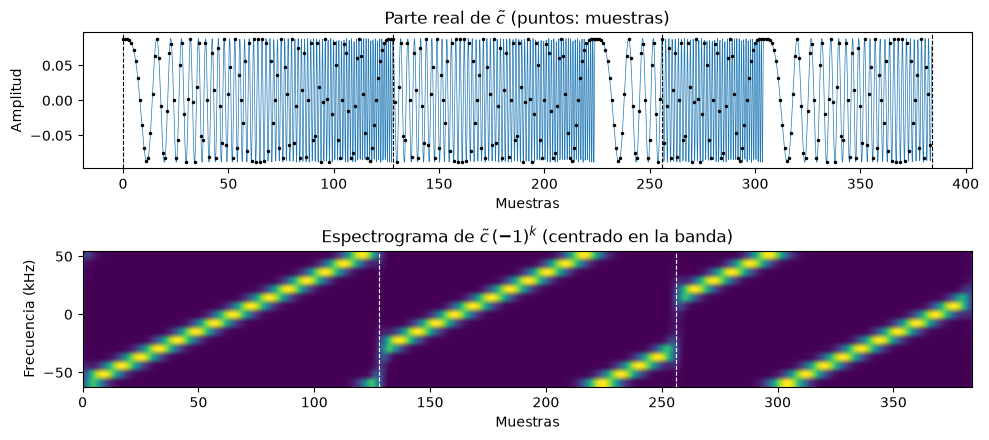

In [17]:
plots.modulated_signal(symbols, p, tx.integrated_modulator, r"\tilde{c}");

**Observaciones**:
- La parte real de $\tilde{c}$ es una onda cosenoidal cuya frecuencia crece a lo largo del símbolo, con un salto donde la frecuencia vuelve a $0$.
- El espectrograma muestra una sola pasada por la banda en cada símbolo, que empieza en $f_0 - B/2$ y por lo tanto es distinta para cada símbolo.

La Ec. 2, en cambio, multiplica $f(k)$ directamente por $kT$. La figura siguiente muestra la señal $c$ que genera el modulador según la Ec. 2, graficada de la misma forma, con la línea que evalúa la Ec. 2 también entre muestras y el espectrograma calculado sobre $c\,(-1)^k$.

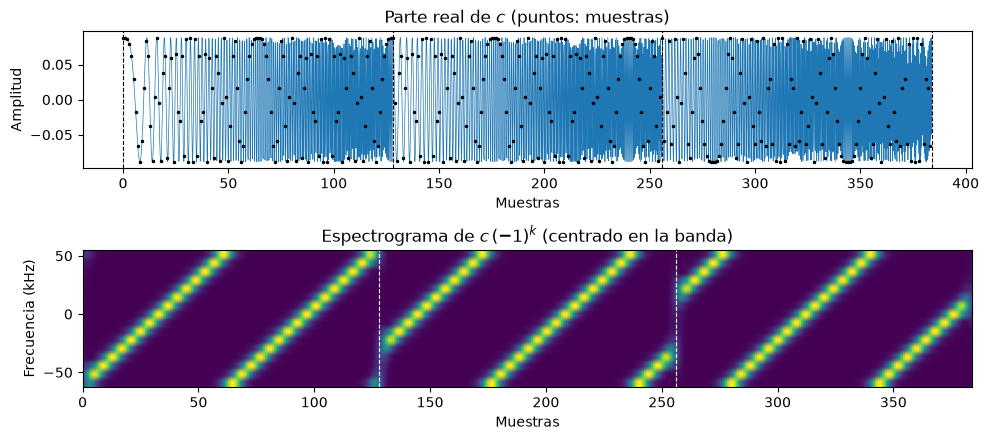

In [18]:
plots.modulated_signal(symbols, p);

**Observaciones**:
- La línea muestra que la Ec. 2 también es un *chirp*, pero su frecuencia crece el doble de rápido que la de $\tilde{c}$ y supera $B$.
- El espectrograma recorre la banda dos veces por símbolo, en lugar de una como el de $\tilde{c}$.

**Diferencia con el *chirp* que describe el paper**:

Una fase $2\pi f t$ tiene frecuencia $f$ solo si $f$ es constante. En la Ec. 2, $f(k)$ crece con $k$ y multiplica a $kT$, que también crece, así que la fase crece con $k^2$ y la frecuencia real crece el doble de rápido, de 0 a $2B$ en $T_s$. Como la señal está muestreada a $B$, una frecuencia $f$ mayor que $B$ da las mismas muestras que $f - B$, un efecto conocido como aliasing. La parte del *chirp* que va de $B$ a $2B$ aparece entonces como una segunda pasada de $0$ a $B$, y por eso el espectrograma muestra dos pasadas por símbolo.

Se decide continuar el desarrollo sobre la Ec. 2 ya que es la señal sobre la que el paper deriva el demodulador y la curva de BER que este trabajo reproduce. Esas derivaciones no usan la forma de la frecuencia, sino solo que las señales de dos símbolos distintos sean ortogonales, es decir, que su producto interno sea nulo (Ec. 4), y el paper lo demuestra para la Ec. 2 tal como está escrita (Ec. 5 a 8). La forma de la frecuencia sí puede influir en la detección de una trama, y en esa parte se señala su efecto.

## Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas. A partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ _chips_ por cada símbolo enviado, el conformador de tuplas produce el arreglo de símbolos recibidos.

Antes de presentar el método formal de demodulación, Vangelista demuestra que el espacio vectorial de las $2^{SF}$ señales que el conformador genera (una por cada posible símbolo) es un espacio vectorial ortogonal.

El método de demodulación propuesto consiste en calcular la correlación cruzada de un tramo de $2^{SF}$ _chips_ de la señal recibida, correspondiente a la transmisión de un símbolo, con cada uno de los vectores de la base de este espacio vectorial (los posibles _chirps_). Puede también interpretarse como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{s(nT_s) = q}$ entre sí.

Dada la ortogonalidad del espacio vectorial, en ausencia de ruido la única correlación distinta de cero es la que corresponde al símbolo recibido, es decir, la correlación de la señal recibida con un _chirp_ idéntico a ella, que equivale a su autocorrelación.

Sobre este método, Vangelista desarrolla una forma computacionalmente más eficiente, descrita en la Ec. 16, que calcula todas las correlaciones cruzadas a la vez:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j2\pi \frac{k^2}{2^{SF}}} \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

La ecuación se puede reescribir como:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} d(nT_s + kT) \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}} = \frac{1}{\sqrt{2^{SF}}}\, \mathrm{DFT}\left\{ d(nT_s + kT) \right\}[q]
$$

donde $d(nT_s + kT)$ es una exponencial compleja de frecuencia constante, igual a la frecuencia inicial del _chirp_ recibido, cuando la señal recibida es un _chirp_ de la Ec. 2:

$$
d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j2\pi \frac{k^2}{2^{SF}}} = \frac{1}{\sqrt{2^{SF}}}\, e^{j2\pi \frac{\left[(s(nT_s) + k) \bmod 2^{SF}\right] k}{2^{SF}}}\, e^{-j2\pi \frac{k^2}{2^{SF}}} = \frac{1}{\sqrt{2^{SF}}}\, e^{j2\pi \frac{s(nT_s)\, k}{2^{SF}}}
$$

Al proceso de multiplicar la señal recibida por el término $e^{-j2\pi \frac{k^2}{2^{SF}}}$, conocido como *down-chirp*, se le llama _de-chirpeado_.

Luego, el paso restante es calcular la sumatoria, que es una Transformada Discreta de Fourier (DFT) y puede computarse mediante la Transformada Rápida de Fourier (FFT). Como $d(nT_s + kT)$ es una exponencial de frecuencia constante, su espectro es un impulso en el bin $q = s(nT_s)$. El demodulador decide entonces el símbolo como el índice del bin de mayor módulo, $\hat{s}(nT_s) = \arg\max_q |\langle r, c|_{s=q} \rangle|^2$, donde $|\langle r, c|_{s=q} \rangle|^2$ es el periodograma de $d(nT_s + kT)$, es decir, una estimación de su densidad espectral de potencia.

Por el teorema de Einstein-Wiener–Khinchin, la densidad espectral de potencia de una señal es la transformada de Fourier de su autocorrelación, lo que permite ver cómo se reparten la señal y el ruido entre los $2^{SF}$ bins. La autocorrelación de una exponencial compleja es otra exponencial de la misma frecuencia, por lo que la densidad espectral de $d(nT_s + kT)$ es un impulso y toda la energía del símbolo cae en el bin $q = s(nT_s)$.

El ruido blanco, por definición, tiene una densidad espectral plana y, por lo tanto, una autocorrelación impulsiva, así que su potencia se reparte en partes iguales entre los $2^{SF}$ bins del espectro. El *down-chirp* no altera esto, porque multiplicar el ruido blanco por una exponencial de módulo 1 no cambia su autocorrelación, y su densidad espectral sigue siendo plana. El _de-chirpeado_ concentra entonces la energía del símbolo en un solo bin mientras el ruido queda repartido en todos, lo que permite decidir correctamente aun cuando la potencia del ruido supera a la de la señal (ver *Detección con ruido en un canal plano*).

Este método asume que la demodulación está sincronizada, es decir, que el receptor ya detectó la trama y conoce dónde empieza cada símbolo, por lo que puede dividir la señal en tramos de $2^{SF}$ _chips_. El proceso de detección se detalla en *Detección de una trama*.

### Decodificación

Una vez generados por el conformador de tuplas, los símbolos recibidos son procesados por el decodificador, que descompone cada uno en un arreglo de $SF$ bits de acuerdo a la Ec. 1, el proceso inverso al descrito en *Codificador*.

#### Visualización del proceso de decisión

##### Recepción sin ruido

Se sigue paso a paso la demodulación de un único símbolo para visualizar cómo el *down-chirp* y la FFT transforman la señal recibida utilizando $SF = 6$, con $2^{SF} = 64$ muestras por símbolo, y $B = 125$ kHz. Se elige el símbolo $s = 20$, distinto de 0 para que $d(nT_s + kT)$ oscile y el impulso no caiga en el bin 0. La figura muestra, de arriba hacia abajo:

1. La parte real de la señal recibida $r(nT_s + kT)$, un *chirp* de la Ec. 2.
2. El espectrograma de $r$ centrado en la banda $B$.
3. La parte real de la señal de-chirpeada $d(nT_s + kT)$, que según *Demodulación* es una exponencial de frecuencia constante igual a $s$ oscilaciones por cada longitud $2^{SF}$ de símbolo.
4. El periodograma $|\langle r, c|_{s=q} \rangle|^2$ que calcula el demodulador, es decir, la estimación de la densidad espectral de potencia de $d$. La línea punteada marca el símbolo decidido $\hat{s}$.

En los gráficos de la parte real la curva evalúa la señal sin ruido entre muestras para visualizar la forma de la onda sin aliasing. Los puntos son las muestras con las que trabaja el receptor.

<!-- TODO(b-Tomas): si Ayarde nos da el OK, usar la fórmula arreglada y sacar la nota del aliasing. Si no, quitar totalemente el primer gráfico -->

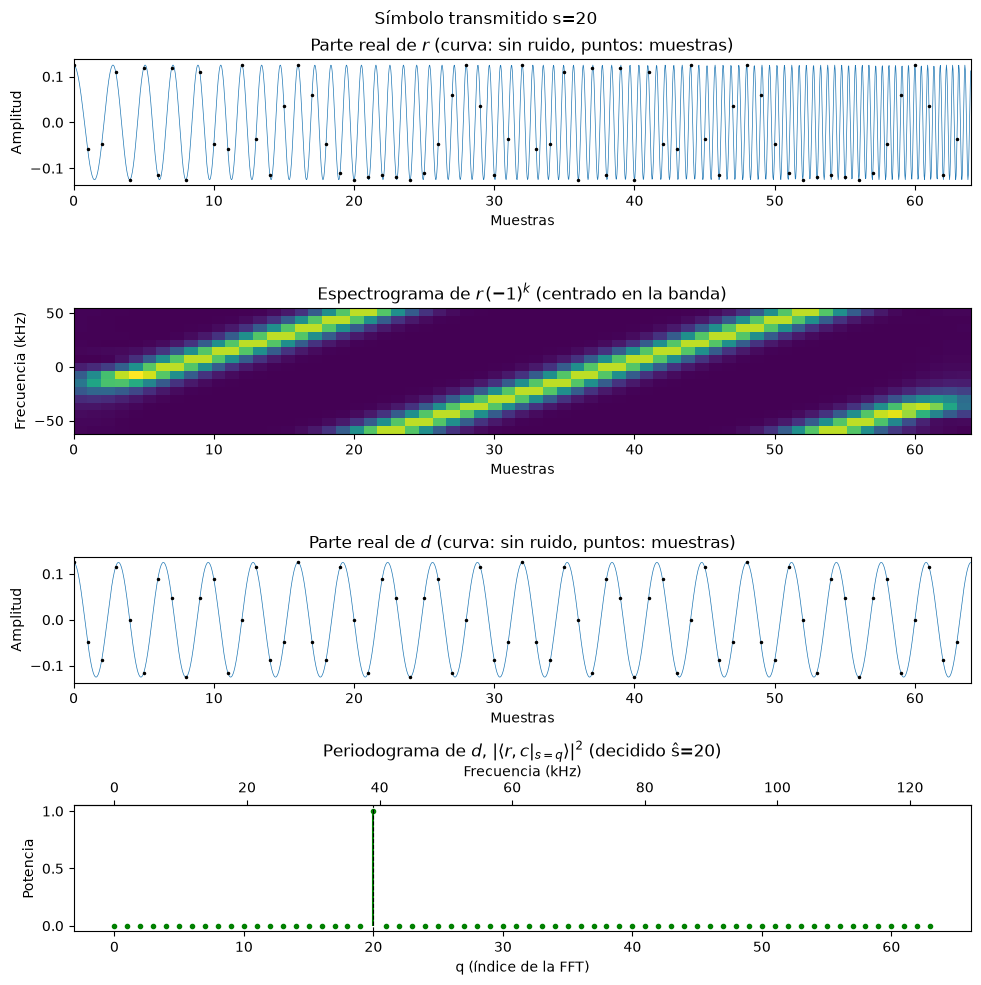

In [19]:
# Demodulación paso a paso de un símbolo sin ruido, con SF = 6
p6 = LoRaParams(SF=6, B=125e3)
s = 20
c_s = tx.modulator(np.array([s]), p6)

plots.dechirp_steps(c_s, s, p6);

**Observaciones**:
- La parte real de $r$ no muestra lo que se espera por la descripción del paper (ver *Análisis de la señal modulada*), un *chirp* cuya frecuencia sube hasta $B$ y vuelve a 0 en $k = 2^{SF} - s = 60$. La frecuencia de la curva sube sin cortes hasta casi $2B$, porque la fase de la Ec. 2 crece con $k^2$. El $\bmod$ de la Ec. 2 no aparece porque en cada muestra resta un número entero de ciclos de fase, así que no cambia las muestras, y la curva se dibuja sin él. <!-- TODO(b-Tomas): si Ayarde nos da el OK, usar la fórmula arreglada. Si no, considerar quitar totalmente esta nota -->
- Después del *down-chirp*, $d$ es una sinusoide de 20 ciclos por símbolo, de frecuencia $20\, B / 2^{SF} \approx 39$ kHz.
- El periodograma es un impulso de valor 1 en $q = 20$, es decir, toda la energía del símbolo cae en un solo bin, como corresponde a la densidad espectral de una exponencial de frecuencia constante.

##### Recepción con ruido

Se repite el mismo símbolo sumándole ruido blanco gaussiano aditivo (AWGN) con un SNR de -3 dB, es decir, con el doble de la potencia de la señal ($10^{-3/10} \approx 0.50$).

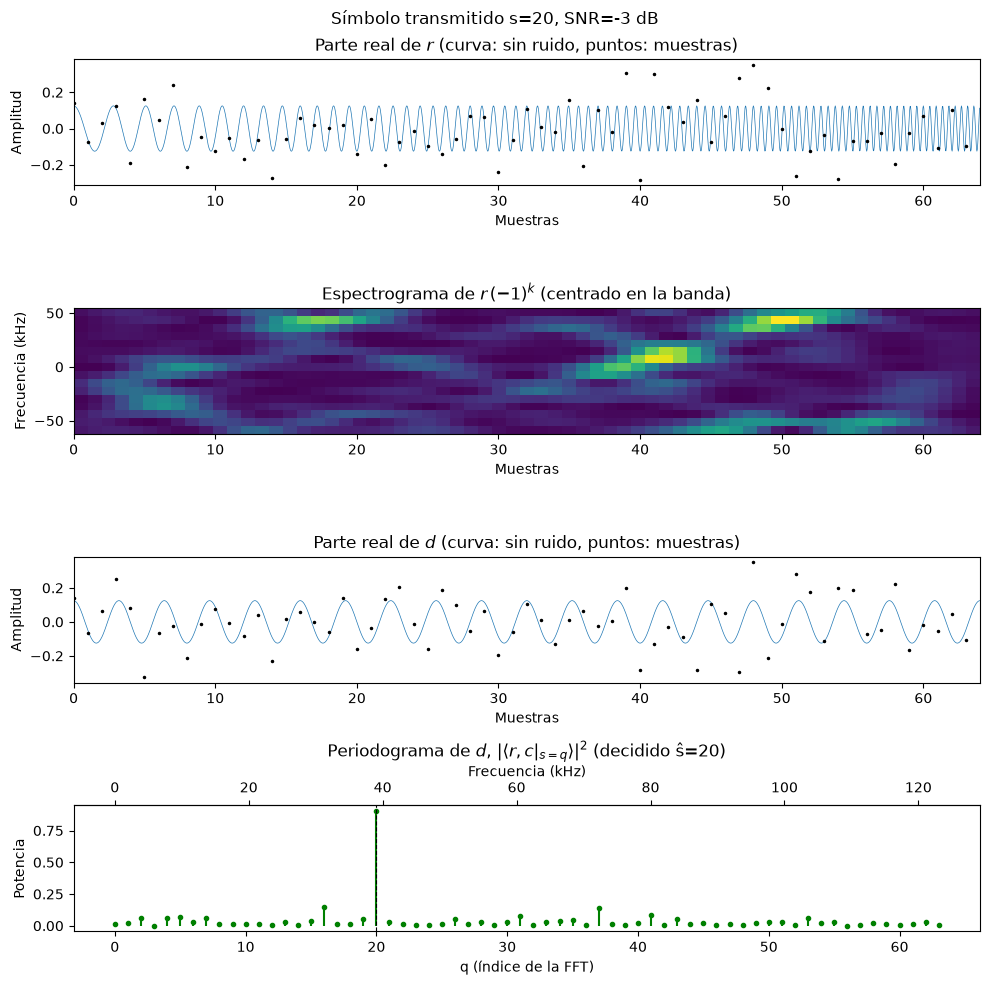

In [20]:
# Demodulación paso a paso del mismo símbolo con ruido
SNR_dB = -3
r = channel.system(c_s, channel.FLAT, channel.noise_from_SNR(c_s, SNR_dB))

plots.dechirp_steps(r, s, p6, SNR_dB)

# Reiniciar la semilla para no alterar los valores aleatorios de las secciones siguientes
seed(0);

**Observaciones**:
- Las muestras de $r$ se apartan de la curva sin ruido y el *chirp* casi no se reconoce en la parte real.
- El espectrograma todavía muestra sus dos pasadas por la banda, aunque con considerablemente menos nitidez.
- En $d$ la sinusoide de 20 ciclos se sigue distinguiendo entre la dispersión de las muestras.
- La energía del símbolo queda concentrada en $q = 20$, marcando un máximo considerablemente por encima de los demás bins donde se observa el ruido, y la decisión es correcta.

## Cálculo del Bit Error Rate (BER)

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

Ya que aún no hemos introducido ruido en el canal, esperamos que el BER sea 0.

In [6]:
# Simular una transmisión completa de 100 símbolos aleatorios
bits_tx = rng.integers(0, 2, size=p.SF * 100)
bits_rx = rx.decoder(rx.demodulator(tx.modulator(tx.encoder(bits_tx, p), p), p), p)
print(f"Bit Error Rate (BER): {metrics.BER(bits_tx, bits_rx):.4f}")

# En caso de corromper un bit:
bits_rx[0] ^= 1  # bit flip
print(f"Bit Error Rate (BER) con un bit corrupto: {metrics.BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


## Potencia de la señal modulada

In [7]:
for SF in [7, 2]:
    q = LoRaParams(SF=SF, B=125e3)
    P = metrics.power(tx.modulator(np.array([0]), q))
    print(f"Potencia de la señal modulada con SF={SF}, B={q.B / 1e3:.0f} kHz: {P:.4f}")

Potencia de la señal modulada con SF=7, B=125 kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125 kHz: 0.2500


## Modelo de canal ruidoso

El canal dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y desplazamiento. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

In [8]:
# Transmisión de 100 símbolos aleatorios por un canal plano
SNR_dB = -10
ber = simulation.transmission_ber(p, SNR_dB, channel.FLAT)
print(f"Bit Error Rate (BER) con SNR={SNR_dB}dB: {ber:.4f}")

Bit Error Rate (BER) con SNR=-10dB: 0.0014


### Detección con ruido en un canal plano

Se repite la simulación de la transmisión y recepción de símbolos, pero esta vez se introduce ruido blanco gaussiano aditivo (AWGN) en el canal.

El canal es plano, es decir, respuesta en frecuencia constante.

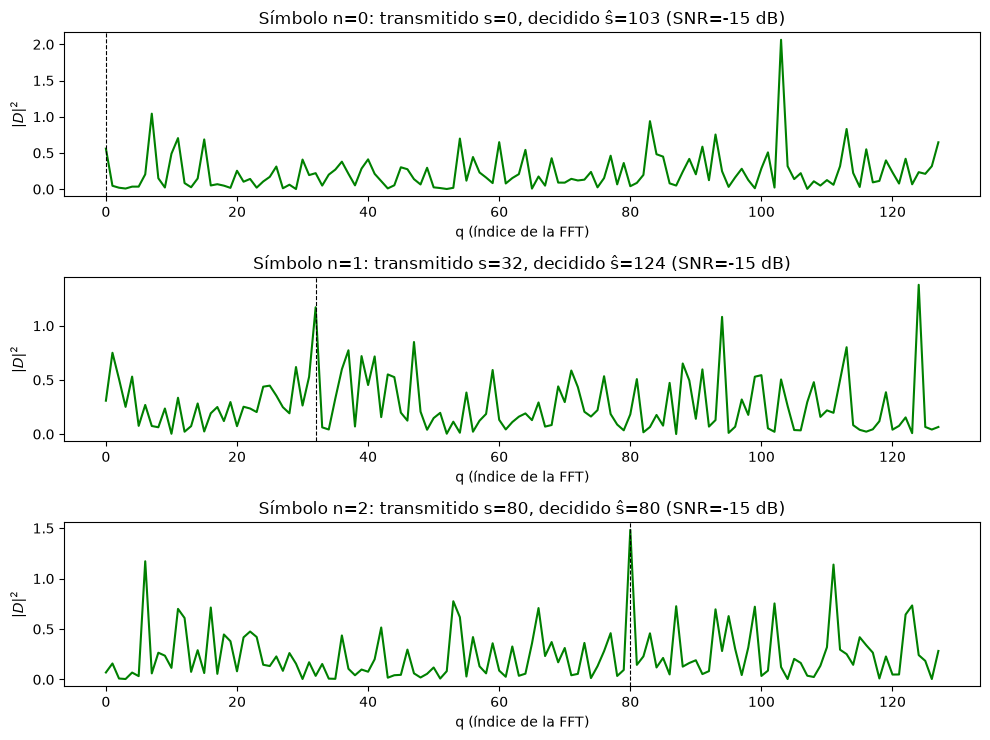

In [9]:
# Probar distintos SNR para ver cuándo empieza a fallar la decisión
SNR_dB = -15
c = tx.modulator(symbols, p)
r = channel.system(c, channel.FLAT, channel.noise_from_SNR(c, SNR_dB))

plots.fft_decision(rx.dechirp_fft(r, p), symbols, rx.demodulator(r, p), SNR_dB);

### Detección con ruido en un canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia. La respuesta al impulso del sistema usado para modelar un canal multicaminos es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$



### Performance de detección

Se analiza el BER vs SNR para el sistema simulado, el cual corresponde a la curva "Flat FSCM" de Fig. 1.

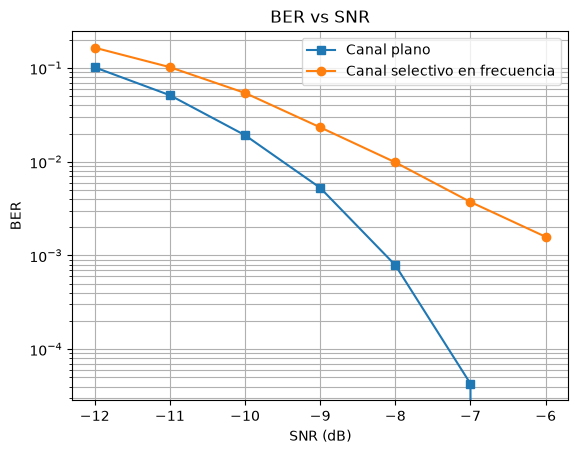

In [10]:
SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -6 dB
simulations = 500  # Transmisiones de 100 símbolos por SNR

bers = {
    "Canal plano": simulation.ber_vs_snr(p, SNRs_dB, channel.FLAT, simulations),
    "Canal selectivo en frecuencia": simulation.ber_vs_snr(
        p, SNRs_dB, channel.FREQ_SELECTIVE, simulations
    ),
}
plots.ber_vs_snr(SNRs_dB, bers);

**Observaciones**:
- En el canal plano el BER cae de $0.1$ a $4 \cdot 10^{-5}$ entre $-12$ y $-7$ dB.
- El canal selectivo en frecuencia necesita más SNR para el mismo BER, y la diferencia crece con el SNR. El eco no se comporta como ruido, porque después del *down-chirp* concentra el 20 % de la potencia en el bin $s - 2$, un competidor fijo del bin del símbolo, y al ruido le alcanza con acercar esos dos bins en lugar de levantar un bin vacío.

## Detección de una trama

En esta sección se analiza el problema de detectar una trama en un canal ruidoso del lado del receptor: decidir si llegó una trama y en qué muestra empieza (sincronización). La trama es un preámbulo de 8 *up-chirps* (símbolos 0) y 2.25 *down-chirps*, seguido del *payload*. Antes de la trama el receptor solo recibe ruido, y no sabe cuándo empieza.

Se plantean tres métodos:

1. **Correlación con el preámbulo completo** (tiempo): filtro adaptado con los 8 *up-chirps*, integración coherente.
2. **Búsqueda de 8 picos** (tiempo): correlación móvil con un solo *up-chirp*, sumando la energía de 8 picos separados un símbolo. Integración no coherente.
3. **Demodulación del preámbulo** (frecuencia): se demodula cada ventana y se cuentan las decididas como símbolo 0.

Para cada método se presenta el estadístico, su umbral de Neyman-Pearson y su aplicación a una trama de ejemplo. Al final se comparan los tres métodos con el *Frame Error Rate* (FER) y la curva ROC.

### Escenario y herramientas comunes

**Parámetros**: desde acá se usa $SF = 8$ y un *payload* de 10 símbolos. Con $SF = 8$ cada símbolo tiene el doble de muestras que con $SF = 7$ y, a igual SNR por muestra, 3 dB más de energía. El receptor escucha 5 símbolos de solo ruido antes de la trama. Cada método se aplica primero a una trama de ejemplo en el canal plano a $-10$ dB, y después se evalúa en función del SNR en el canal plano y en el selectivo en frecuencia.

**Umbral**: los tres métodos fijan el umbral con el criterio de Neyman-Pearson para la misma probabilidad de falsa alarma por símbolo, $P_{FA}$. Su valor sale de la tasa de falsas alarmas que tolera el receptor, porque cada falsa alarma hace que intente demodular una trama que no existe y, mientras tanto, puede perder una real. El receptor evalúa $B / 2^{SF}$ símbolos por segundo, así que para tolerar $R_{FA}$ falsas alarmas por segundo

$$
P_{FA} = R_{FA}\, \frac{2^{SF}}{B}
$$

Con una falsa alarma por minuto, $R_{FA} = 1/60\ \text{s}^{-1}$, resulta $P_{FA} \approx 3.4 \cdot 10^{-5}$ por símbolo. Se asume que el receptor conoce la potencia del ruido $\sigma^2$, que en la práctica se estima mientras no hay señal.

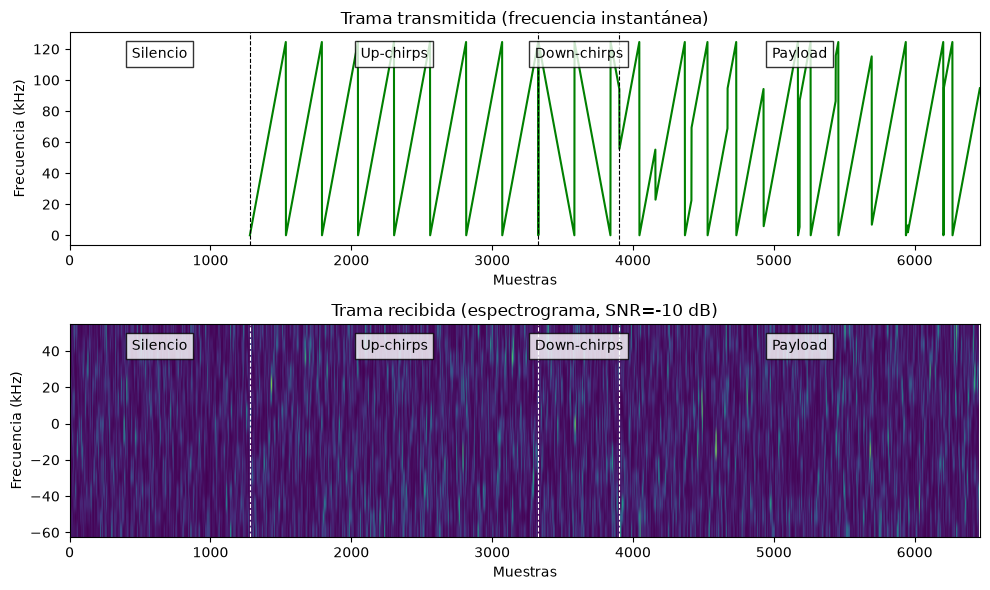

In [11]:
# Escenario para analizar las estrategias de detección
p = LoRaParams(SF=8, B=125e3)
num_symbols = 10  # Símbolos del payload
SNR_dB = -10
gap = 5  # Símbolos de silencio antes de la trama: desconocido para el receptor
symbols_tx = rng.integers(0, p.M, size=num_symbols)
R_FA = 1 / 60  # Tasa de falsas alarmas tolerable: una por minuto
P_FA = R_FA * p.Ts  # Probabilidad de falsa alarma por símbolo

r = channel.transmit_frame(symbols_tx, gap, p, SNR_dB, channel.FLAT)
r_clean = channel.transmit_frame(symbols_tx, gap, p, 100, channel.FLAT)  # Sin ruido apreciable
noise_power = channel.noise_power(p, SNR_dB)  # sigma^2, conocida por el receptor

plots.frame_structure(r, symbols_tx, gap, p, SNR_dB);

### Detección en el tiempo: correlación móvil con un up-chirp

En el tiempo el receptor no necesita sincronía de símbolo: desliza una plantilla conocida sobre la señal recibida, muestra a muestra, y busca dónde se parece más. La muestra $k$ donde se decide $H_1$ es a la vez la detección y la sincronización, porque es donde empieza la trama.

Para cada muestra $k$ se plantea un test de hipótesis binario:

- $H_0$: el preámbulo no empieza en la muestra $k$. Se recibe solo ruido, u otra parte de la trama.
- $H_1$: el preámbulo empieza en la muestra $k$, y $r_k = p + w$, donde $r_k$ son las muestras recibidas a partir de $k$, $p$ son los 8 *up-chirps* del preámbulo (conocidos) y $w$ es ruido gaussiano i.i.d.

Los dos métodos parten de la correlación móvil de la señal recibida con un solo *up-chirp* (símbolo 0):

$$
y[k] = \langle r_k, c|_{s=0} \rangle = \sum_{i=0}^{2^{SF}-1} r(kT + iT)\, c^*(iT)|_{s=0}
$$

Dentro del preámbulo, $|y[k]|^2$ es máxima cuando la plantilla queda alineada con un *up-chirp*, y nula con cualquier otro desplazamiento, porque un *up-chirp* desplazado en el tiempo es un *up-chirp* con un corrimiento de frecuencia, ortogonal al original.

Los picos aparecen cada $2^{SF}/2$ muestras y no cada $2^{SF}$. Como se vio en *Análisis de la señal modulada*, la frecuencia de la Ec. 2, cuya fase para el símbolo 0 es $2\pi k^2 / 2^{SF}$, barre de 0 a $2B$ y, muestreada a $B$, se repliega. Cada *up-chirp* son dos copias de un *chirp* de $2^{SF}/2$ muestras, y el preámbulo produce 16 picos.

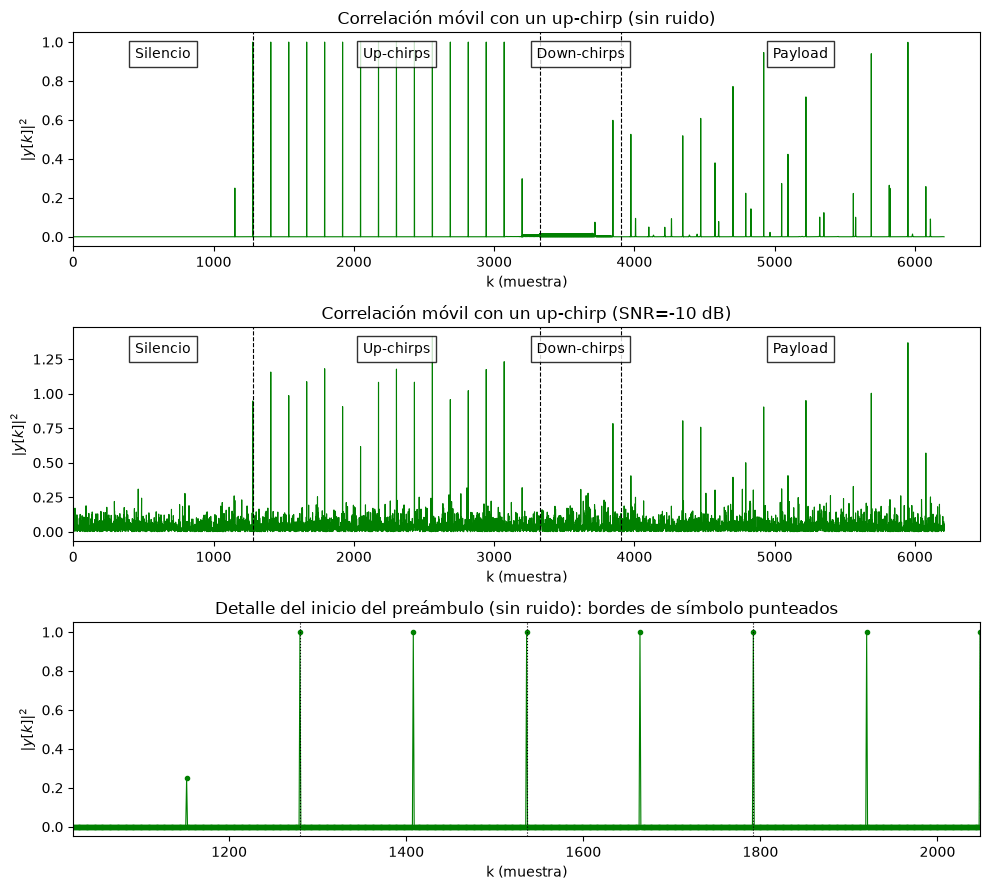

In [12]:
# Correlación móvil con un up-chirp sobre la trama del escenario, sin ruido y con ruido
y_clean = detection.upchirp_correlation(r_clean, p)
y = detection.upchirp_correlation(r, p)

plots.upchirp_correlation(y_clean, y, gap, p, SNR_dB);

**Observaciones**:
- Sin ruido se ve la estructura de la trama: picos de altura 1 cada $2^{SF}/2$ muestras durante los *up-chirps*, nada en el silencio ni en los *down-chirps*, y picos aislados en el *payload* (donde un símbolo, o una mezcla de dos símbolos consecutivos, se parece a un *up-chirp*).
- Con ruido los picos del preámbulo siguen sobresaliendo, pero el ruido también produce picos: decidir con uno solo daría muchas falsas alarmas. Los dos métodos en el tiempo combinan los 8 picos que deja el preámbulo, separados un símbolo: uno en forma coherente y otro no coherente.

### Detección en el tiempo: correlación con el preámbulo completo

La plantilla es el preámbulo completo de 8 *up-chirps*, $p$. Es el problema de detectar una señal conocida en ruido gaussiano, donde el test de razón de verosimilitud se reduce a correlar la señal recibida con la señal conocida (filtro adaptado) y comparar con un umbral. Como la fase de la señal recibida es desconocida, se compara el módulo al cuadrado:

$$
T[k] = \left| \langle r_k, p \rangle \right|^2 = \left| \sum_{n=0}^{7} y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta
$$

Como $p$ son *up-chirps* repetidos, correlar con $p$ es sumar los 8 picos de $y[k]$ separados un símbolo. La suma es coherente, antes del módulo, así que las amplitudes de la señal se suman en fase (potencia $\times 64$) mientras que las potencias del ruido se suman ($\times 8$), una ganancia de $10\log_{10} 8 \approx 9$ dB respecto de un solo pico. A cambio, necesita que la fase de la señal se mantenga durante los 8 símbolos, lo que un corrimiento de frecuencia entre transmisor y receptor impediría.

**Umbral (Neyman-Pearson)**: no se conocen las probabilidades *a priori* de $H_0$ y $H_1$, así que se fija la $P_{FA}$ tolerable. Cada *chirp* tiene energía 1, así que bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, la suma de 8 tiene varianza $8\sigma^2$ y $T[k]$ tiene distribución exponencial de media $8\sigma^2$:

$$
P_{FA} = P(T[k] > \eta \mid H_0) = e^{-\eta / 8\sigma^2} \quad\Rightarrow\quad \eta = -8\sigma^2 \ln P_{FA}
$$

El test se repite en las $2^{SF}$ muestras de cada símbolo, así que para tener la misma tasa de falsas alarmas que un test por símbolo se usa $P_{FA} / 2^{SF}$ en cada muestra.

**Inicio de la trama**: cada $2^{SF}/2$ muestras la plantilla vuelve a alinearse con parte del preámbulo, así que alrededor del inicio $T[k]$ es un peine, con $T \approx 64\,(1 - j/16)^2$ cuando quedan $j$ medios *chirps* afuera. El primer cruce del umbral suele ser uno de estos picos laterales, antes del inicio, así que el inicio se estima como el máximo de $T[k]$ en los 8 símbolos siguientes al primer cruce. La búsqueda se repite desde ese máximo hasta que ningún valor de los 8 símbolos siguientes lo supere, por si el primer cruce llega más de 8 símbolos antes del inicio, como ocurre en el SDR (ver *SNR y FER según la atenuación del TX*).

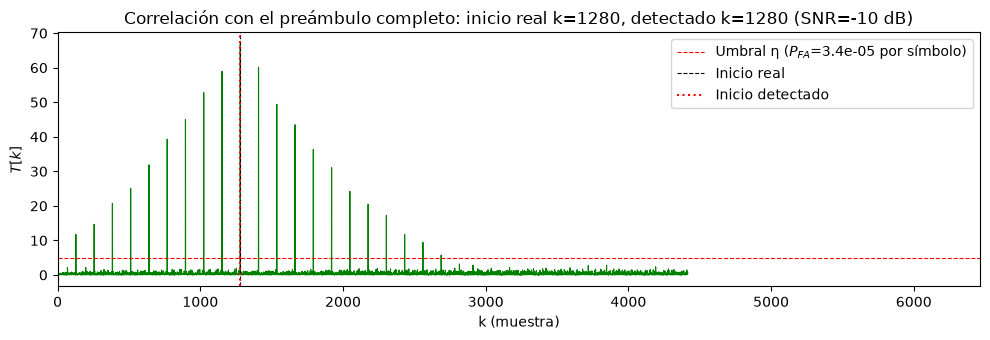

In [13]:
# Correlación con el preámbulo completo sobre el escenario
eta = detection.threshold("full", p, noise_power, P_FA)
T = detection.preamble_correlation(r, p)
start = detection.detect_start(T, eta, p.n_upchirps * p.M)

plots.full_preamble_detection(T, eta, start, gap, p, P_FA, SNR_dB);

### Detección en el tiempo: búsqueda de 8 picos

En lugar de un pico de la correlación con el preámbulo completo, se buscan los 8 picos seguidos, separados un tiempo de símbolo ($2^{SF}$ muestras), que deja el preámbulo en la correlación móvil con un solo *up-chirp*. El estadístico suma la energía de los 8 picos candidatos a partir de la muestra $k$:

$$
S[k] = \sum_{n=0}^{7} \left| y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_S
$$

La diferencia con $T[k]$ es dónde se toma el módulo. $T[k]$ suma los picos y después toma el módulo (integración coherente); $S[k]$ toma el módulo de cada pico y después suma (integración no coherente). Al sumar energías se descarta la fase de cada pico, así que el método tolera que la fase cambie entre símbolos. A cambio, el ruido de cada pico suma su energía en lugar de promediarse con el de los demás, y se espera que necesite más SNR que $T[k]$.

Los picos intermedios, a $2^{SF}/2$ muestras, no se usan. Con picos separados un símbolo las 8 correlaciones usan muestras disjuntas, y bajo $H_0$ son independientes.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, así que $|y|^2$ es exponencial de media $\sigma^2$. Los 8 son independientes, por lo que $S[k]$ tiene distribución Gamma de orden 8 (Erlang) y escala $\sigma^2$, con cola en forma cerrada:

$$
P_{FA} = P(S[k] > \eta_S \mid H_0) = e^{-\eta_S/\sigma^2} \sum_{i=0}^{7} \frac{(\eta_S/\sigma^2)^i}{i!}
$$

$\eta_S$ no se puede despejar, pero como la cola es decreciente en $\eta_S$, se busca por bisección. Igual que en $T[k]$, se usa $P_{FA} / 2^{SF}$ por muestra.

**Inicio de la trama**: $S[k]$ también es un peine alrededor del inicio, y el inicio se estima de la misma forma. Sus picos laterales son más altos, relativos al principal, que los de $T[k]$. Con medio símbolo de error $S \approx 7.25$, contra 8 en el inicio, mientras que $T$ baja de 64 a $\approx 56$.

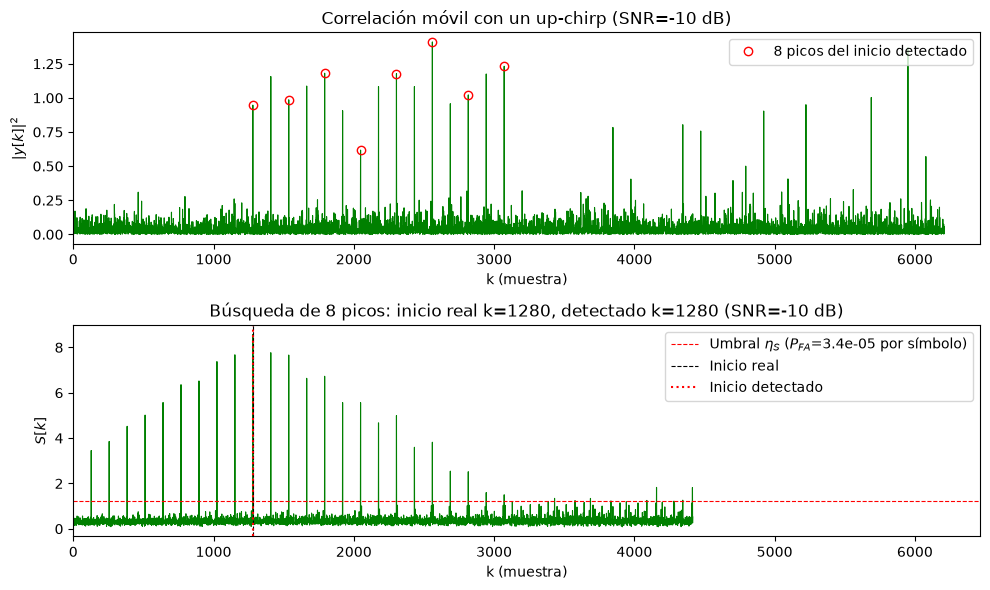

In [14]:
# Búsqueda de 8 picos sobre el escenario
eta_S = detection.threshold("peaks", p, noise_power, P_FA)
S = detection.peaks_statistic(r, p)
start = detection.detect_start(S, eta_S, p.n_upchirps * p.M)

plots.peaks_detection(y, S, eta_S, start, gap, p, P_FA, SNR_dB);

### Detección en frecuencia: demodulación del preámbulo

A diferencia de la detección en el tiempo, se asume sincronía de símbolo. El receptor divide la señal recibida en ventanas de $2^{SF}$ muestras alineadas con los bordes de los símbolos, y lo que no conoce es en qué ventana $m$ empieza la trama. Las hipótesis son las mismas que en el tiempo, por ventana en lugar de por muestra.

La estrategia en frecuencia reutiliza el demodulador (Ec. 16): cada ventana se multiplica por el *down-chirp* y se calcula su FFT. Durante el preámbulo cada ventana es un *up-chirp* de símbolo 0, por lo que el pico de la FFT aparece en el bin $q = 0$.

Mirar solo el bin 0 no aporta nada nuevo, porque $D_n[0]$ es la correlación móvil $y[k]$ de la detección en el tiempo evaluada en el borde de la ventana, $k = n\,2^{SF}$. La diferencia está en comparar el bin 0 con los demás bins en vez de con un umbral absoluto. El estadístico es la cantidad de ventanas, entre 8 consecutivas, en las que el demodulador decide el símbolo $\hat{s}[n] = 0$:

$$
V[m] = \sum_{n=m}^{m+7} \mathbb{1}\{\hat{s}[n] = 0\} \;\underset{H_0}{\overset{H_1}{\gtrless}}\; K
$$

Un umbral $K < 8$ tolera ventanas del preámbulo mal decididas por el ruido. El inicio se estima igual que en el tiempo: el máximo de $V[m]$ después del primer cruce.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada ventana es ruido blanco gaussiano, y su FFT (unitaria) también lo es, así que el máximo cae en cualquiera de los $2^{SF}$ bins con igual probabilidad y cada ventana se decide como símbolo 0 con probabilidad $p_0 = 2^{-SF}$. El ruido de ventanas distintas es independiente, por lo que $V[m]$ tiene distribución binomial $\mathcal{B}(8, p_0)$:

$$
P_{FA}(K) = P(V[m] \geq K \mid H_0) = \sum_{k=K}^{8} \binom{8}{k} p_0^k (1 - p_0)^{8-k}
$$

$V[m]$ es discreto, así que en general ningún $K$ da exactamente la $P_{FA}$ pedida. Bajar el umbral sube la $P_D$, por lo que Neyman-Pearson elige el menor $K$ con $P_{FA}(K) \leq P_{FA}$. Hay un test por ventana, así que $P_{FA}$ se usa sin dividir. Para $SF = 8$ y $P_{FA} \approx 3.4 \cdot 10^{-5}$, $P_{FA}(2) \approx 4.2 \cdot 10^{-4}$ no la respeta y $P_{FA}(3) \approx 3.3 \cdot 10^{-6}$ sí, así que $K = 3$, con una $P_{FA}$ unas 10 veces menor que la tolerada.

- **Ventaja**: el umbral no depende de $\sigma^2$, ya que la decisión de cada ventana es relativa entre bins y la distribución de $V[m]$ bajo $H_0$ solo depende de $SF$. No hace falta conocer ni estimar la potencia del ruido.
- **Desventaja**: cada ventana toma una decisión dura con la energía de un solo símbolo, y se pierde la ganancia de 9 dB de la suma coherente. Se espera que necesite más SNR que la detección en el tiempo.
- **Empates**: con probabilidad $2^{-SF}$ la ventana de ruido justo antes del preámbulo también se decide como símbolo 0, y $V[m]$ empata en 8 con el inicio real. Se elige la primera ventana del empate, un error de $\approx 0.4\%$ que no baja con el SNR. En el tiempo no hay empates, porque $T[k]$ es continuo.

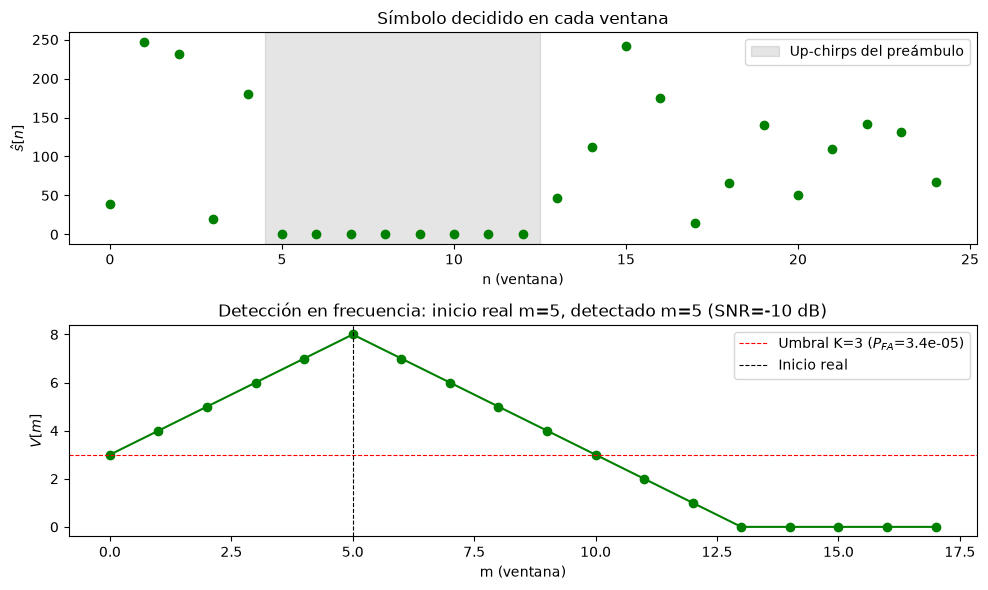

In [15]:
# Detección en frecuencia sobre el escenario
K = detection.threshold("freq", p, noise_power, P_FA)
V = detection.preamble_zero_count(r, p)
start = detection.detect_start(V, K, p.n_upchirps)

# Símbolo decidido en cada ventana, para ver qué ventanas cuentan en V[m]
symbols_rx = rx.demodulator(r[: r.size // p.M * p.M], p)

plots.freq_detection(symbols_rx, V, K, start, gap, p, P_FA, SNR_dB);

### Comparación de los métodos

#### Frame Error Rate (FER)

El *Frame Error Rate* (FER) es la fracción de tramas cuyo inicio el receptor no estima en la muestra exacta, ya sea porque no detecta la trama (*miss*), porque se adelanta (falsa alarma) o porque se atrasa. Un inicio corrido una sola muestra cuenta como error, porque el demodulador corta los símbolos del *payload* a partir de él. Los errores del *payload* con el inicio correcto no cuentan, porque los mide el BER (ver *Performance de detección*).

Se simula el FER de los tres métodos en ambos canales. Junto con la ROC, es la métrica para comparar los detectores. El FER cae varios órdenes de magnitud en pocos dB, así que el eje es logarítmico. Cada SNR se simula hasta juntar 30 tramas perdidas o llegar a 2000 tramas, así que el menor FER que se puede medir es $1/2000 = 5 \cdot 10^{-4}$, y los puntos sin errores no se dibujan.

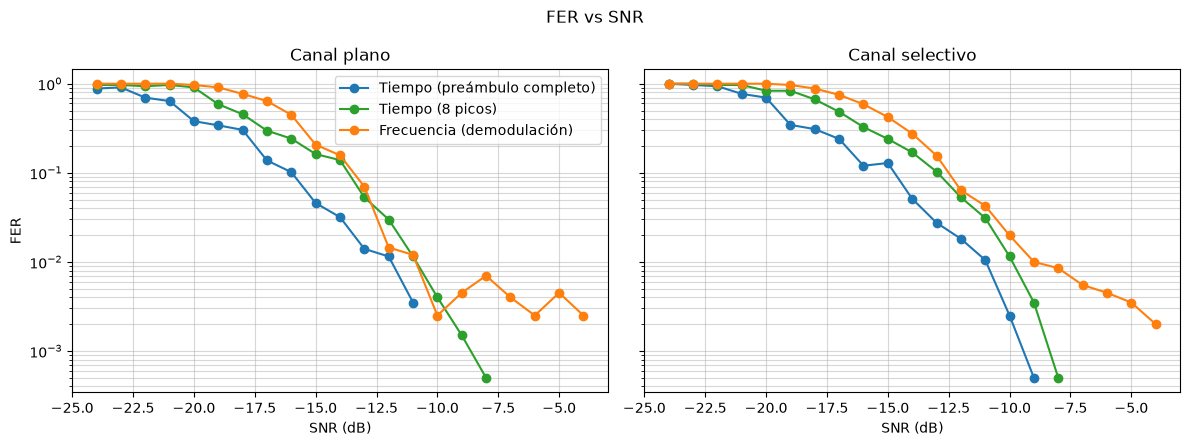

In [16]:
SNRs_fer_dB = np.arange(-24.0, -3.0, 1.0)  # -24 a -4 dB
detectors = {
    "full": detection.detect_full,
    "peaks": detection.detect_peaks,
    "freq": detection.detect_freq,
}

fer_flat, fer_sel = {}, {}
for method, detect in detectors.items():
    for fer, h in ((fer_flat, channel.FLAT), (fer_sel, channel.FREQ_SELECTIVE)):
        fer[method] = simulation.fer_vs_snr(
            detect, SNRs_fer_dB, h, p, P_FA, 2000, num_symbols=num_symbols, gap=gap, min_errors=30
        )

plots.compare_methods(SNRs_fer_dB, fer_flat, fer_sel, "FER", "FER vs SNR", logy=True);

**Observaciones**:
- Orden de los métodos, en ambos canales: correlación con el preámbulo completo, búsqueda de 8 picos y demodulación del preámbulo, con unos 2 dB entre cada uno (FER de 0.5 cerca de $-20$, $-18$ y $-16$ dB en el canal plano).
- **Integración coherente contra no coherente**: los dos métodos en el tiempo usan los mismos 8 picos de $y[k]$. Sumarlos antes del módulo (preámbulo completo) gana unos 2 dB frente a sumar sus energías (8 picos), a cambio de necesitar que la fase se mantenga durante el preámbulo.
- **Decisión blanda contra decisión dura**: los métodos en el tiempo conservan cuánto se parece cada posición a un *up-chirp*. La demodulación reduce cada ventana a "símbolo 0 o no", perdiendo información, y además necesita sincronía de símbolo.
- En el tiempo, por debajo de un FER de $\approx 0.4$ la caída se hace más lenta (con el preámbulo completo, de 0.38 a $-20$ dB a 0.30 a $-18$ dB). Las tramas ya se detectan, pero algunas con el inicio en un pico lateral del peine, medio símbolo o un símbolo corrido (ver *Detección en el tiempo: correlación con el preámbulo completo* y *FER por el aire*). Los picos laterales a medio símbolo aparecen porque la frecuencia de la Ec. 2 recorre la banda dos veces por símbolo (ver *Análisis de la señal modulada*). Con un *chirp* de una sola pasada, como $\tilde{c}$, la plantilla corrida medio símbolo no vuelve a alinearse, así que este tramo podría ser distinto.
- La demodulación del preámbulo tiene un piso de entre $2 \cdot 10^{-3}$ y $7 \cdot 10^{-3}$ desde $-10$ dB, por los empates descriptos en la detección en frecuencia ($\approx 0.4\%$). Los métodos en el tiempo no tienen piso, y en el canal plano desde $-7$ dB no pierden ninguna trama en 2000.
- El canal selectivo desplaza todas las curvas $\approx 1$ dB sin cambiar el orden. La plantilla solo captura el camino principal, que lleva el 80 % de la energía ($10\log_{10} 0.8 \approx -1$ dB).
- La correlación con el preámbulo completo es también la más costosa, porque aplica en cada muestra un filtro de $8 \cdot 2^{SF}$ coeficientes. La demodulación del preámbulo, en cambio, reutiliza el demodulador, con una FFT por símbolo.

#### Curva ROC

El FER mezcla detección y localización, porque una trama detectada con el inicio corrido también se pierde. Para comparar los métodos solo como detectores se usa el test binario en una posición (una muestra en el tiempo, una ventana en frecuencia):

- $H_0$: los 8 símbolos a partir de la posición contienen solo ruido.
- $H_1$: la posición está alineada con el inicio del preámbulo.

Cada umbral define un punto de operación ($P_{FA}$, $P_D$), con $P_D = P(\text{'}H_1\text{'} \mid H_1)$. La curva ROC (*Receiver Operating Characteristic*) recorre todos los umbrales y muestra el compromiso entre ambas probabilidades, ya que subir el umbral reduce las falsas alarmas a costa de perder detecciones. Neyman-Pearson elige el punto de la curva con la mayor $P_D$ que respeta la $P_{FA}$ tolerable (estrellas), y un detector es mejor que otro si su curva queda por encima.

El eje es la $P_{FA}$ por símbolo. En el tiempo se prueban $2^{SF}$ posiciones por símbolo, así que su tasa de falsas alarmas por símbolo es $2^{SF}$ veces la $P_{FA}$ por muestra, y con este eje los tres métodos se comparan a la misma tasa. Como la distribución de cada estadístico bajo $H_0$ es conocida, la $P_{FA}$ se calcula con el umbral (ver *Anexo A: falsas alarmas*) y solo se estima $P_D$. Las curvas empíricas (punteadas), que estiman también la $P_{FA}$, validan las teóricas donde se pueden medir. La curva de la detección en frecuencia es una escalera, porque $V[m]$ solo toma 9 valores.

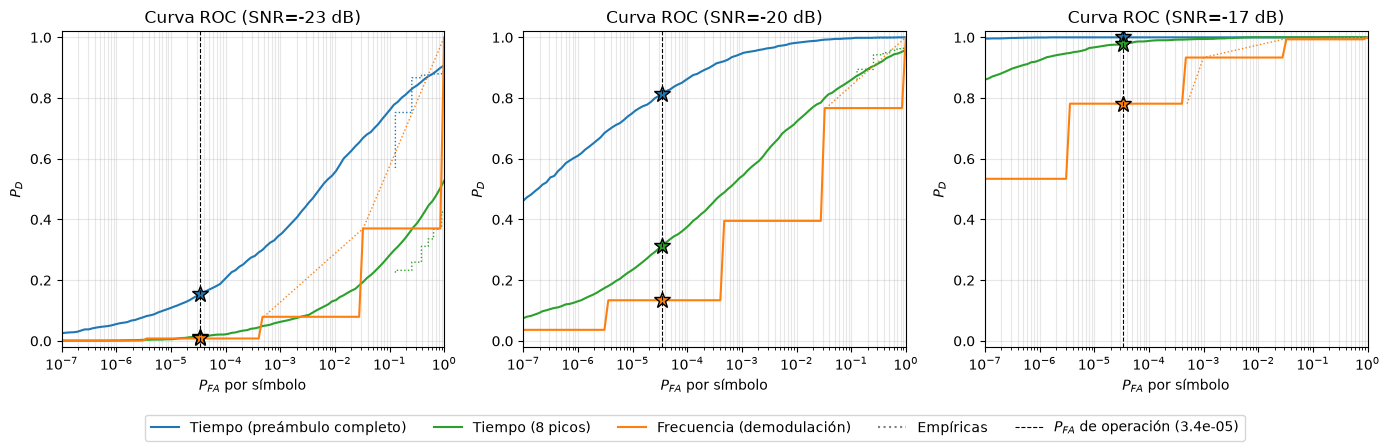

In [17]:
SNRs_roc_dB = [-23.0, -20.0, -17.0]  # Un gráfico por SNR, en el rango donde cambia la detección
simulations_roc = 2000  # Realizaciones por hipótesis
P_FA_axis = np.logspace(-7, 0, 100)  # P_FA por símbolo

roc_curves = {
    SNR: simulation.roc_curves(p, SNR, simulations_roc, P_FA_axis, P_FA) for SNR in SNRs_roc_dB
}
plots.roc(roc_curves, P_FA_axis, P_FA);

**Observaciones**:
- En el punto de operación, a $-20$ dB, la correlación con el preámbulo completo detecta con $P_D \approx 0.8$, la búsqueda de 8 picos con $\approx 0.3$ y la demodulación con $\approx 0.13$. La correlación con el preámbulo completo queda por encima de las demás para cualquier $P_{FA}$ y SNR.
- Entre la búsqueda de 8 picos y la demodulación el orden depende de la $P_{FA}$. Con $P_{FA}$ altas y SNR bajo la demodulación puede superar a la búsqueda de 8 picos, porque prueba una sola posición por símbolo y necesita un umbral más bajo para la misma tasa de falsas alarmas.
- En la demodulación la $P_D$ cae a escalones: con 9 umbrales posibles, la $P_{FA}$ de operación obliga a $K = 3$.
- El test en una posición funciona a menor SNR que la detección del inicio (a $-20$ dB, la correlación con el preámbulo completo tiene $P_D \approx 0.8$ pero un FER de $\approx 0.4$), porque encontrar el inicio exige además que la posición correcta supere a las vecinas.

## Prueba en el SDR

Hasta acá el receptor se evaluó por simulación. En este capítulo se prueba con un SDR (*software defined radio*), un equipo que transmite y recibe las muestras que genera y procesa la PC, en tres pasos:

1. **Loopback digital**: el SDR devuelve las muestras transmitidas sin pasar por el canal, y se verifica el software sin ruido.
2. **SNR y FER según la atenuación del TX**: se mide el SNR del equipo con distintas potencias de transmisión, para saber si llega al rango donde cambia el FER.
3. **FER por el aire**: se baja la señal hasta que la limite el ruido térmico del RX, y se compara el FER medido con la simulación.

Se usa un solo detector, la correlación con el preámbulo completo, que fue el de menor FER en la simulación (ver *Frame Error Rate (FER)*).

### Configuración del experimento

El SDR es un ADALM-Pluto del laboratorio, al que se accede por una VPN. El mismo equipo transmite (TX) y recibe (RX), así que ambos comparten el oscilador local y la señal llega sin corrimiento de frecuencia.

Se usan los mismos parámetros que en la sección del FER, $SF = 8$ y tramas de 10 símbolos de *payload*, con una portadora de 905 MHz. El ancho de banda es $B = 1$ MHz, con una muestra por chip, dentro del rango de muestreo del Pluto (de 521 kHz a 61.44 MHz según el material del laboratorio). Como el SNR de la simulación es por muestra, la curva de FER vs SNR no depende de $B$, y el resultado vale también para los 125 kHz de LoRa.

El TX repite sin pausa un buffer de varias tramas, 50 para medir el SNR y 200 para el FER. Antes de cada trama hay un silencio de largo al azar, de 5 a 10 símbolos, para que el receptor no pueda predecir dónde empieza la siguiente. El RX graba una captura que contiene todas las tramas del buffer.

El receptor recorre la captura sin saber dónde están las tramas. En cada tramo busca un preámbulo con el detector y, si lo encuentra, estima el inicio de la trama. El umbral del detector se calcula con la potencia del ruido medida en los silencios, como si el receptor la estimara mientras el canal está libre. La medición, que sí conoce lo transmitido, ubica el buffer en la captura y compara el inicio real de cada trama con el inicio detectado más cercano. Los detalles de la transmisión y del recorrido de la captura están en *Anexo B: transmisión y recepción de las tramas*.

In [18]:
import numpy as np

from lora import LoRaParams, channel, detection, plots, sdr, simulation

# False: usa las capturas guardadas en captures/ (no necesita el SDR ni la VPN)
# True: mide con el SDR del laboratorio y sobrescribe captures/
USE_SDR = False
URI = "ip:192.168.1.32" if USE_SDR else None

p_sdr = LoRaParams(SF=8, B=1e6)
num_symbols = 10  # Símbolos del payload
gap_range = (5, 10)  # Largo del silencio antes de cada trama, en símbolos
P_FA = 1 / 60 * p_sdr.Ts  # Una falsa alarma por minuto
N_FRAMES = 200  # Tramas por punto del FER
FER_RANGE_dB = np.array([-22.0, -10.0])  # Donde el FER simulado pasa de 1 a 10^-3

### Loopback digital

En loopback digital, el Pluto devuelve al RX las muestras del TX sin convertirlas en una señal analógica, así que no hay ruido ni canal. Se espera detectar el inicio de todas las tramas en la muestra exacta, y cualquier error indica una falla del software.

In [19]:
def run_loopback(pluto):
    symbols, gaps, r, _ = sdr.measure(pluto, p_sdr, 10, num_symbols, gap_range, calibrate=False)
    return r, {"symbols": symbols, "gaps": gaps}


r_loop, meta_loop = sdr.acquire("captures/loopback.npz", run_loopback, p_sdr, URI, loopback=1)
ev_loop = sdr.evaluate(r_loop, meta_loop["symbols"], meta_loop["gaps"], p_sdr, P_FA)
print(f"Loopback digital: {ev_loop.errors.sum()} de {ev_loop.errors.size} tramas perdidas")

Loopback digital: 0 de 10 tramas perdidas


**Observaciones**:
- Las 10 tramas se detectan con el inicio en la muestra exacta, así que el armado de las tramas, la escala de las muestras, el manejo de los buffers y el receptor funcionan.

### SNR y FER según la atenuación del TX

En la simulación, el FER pasa de casi 1 a casi 0 entre $-22$ y $-10$ dB de SNR (ver *Frame Error Rate (FER)*). Para saber si el equipo llega a ese rango, se transmiten 50 tramas con cada atenuación del TX y se miden el SNR y el FER. La ganancia del RX la elige el control automático de ganancia (AGC) del Pluto antes de cada captura, y después queda fija para que el silencio, donde se estima la potencia del ruido para el umbral, y la trama se reciban con la misma ganancia (ver *Anexo B: fondo de escala del ADC*).

El SNR se estima comparando la captura con lo transmitido. Con el buffer transmitido $x$ y la captura $r$ alineada con él, ambos de $N$ muestras, la amplitud compleja $\hat a$ con que llega la señal se estima por mínimos cuadrados, y lo que queda al restar la señal es el ruido:

$$
\hat a = \frac{\langle x, r \rangle}{\langle x, x \rangle}, \qquad
\hat\sigma^2 = \frac{\| r - \hat a\, x \|^2}{N}, \qquad
SNR = \frac{|\hat a|^2 P_{trama}}{\hat\sigma^2}
$$

donde $P_{trama}$ es la potencia de la trama, la misma referencia que en la simulación. El ruido estimado $\hat\sigma^2$ incluye el ruido térmico del RX, la cuantización y la distorsión del equipo, todo lo que no es la señal transmitida.

Si el SNR queda por encima del rango aun con la máxima atenuación, hace falta bajar la señal de otra forma.

Atenuación  -10 dB: ganancia 15 dB, SNR  16.4 dB, FER 0.00
Atenuación  -30 dB: ganancia 35 dB, SNR  14.0 dB, FER 0.00
Atenuación  -50 dB: ganancia 53 dB, SNR  14.1 dB, FER 0.00
Atenuación  -70 dB: ganancia 72 dB, SNR  14.0 dB, FER 0.00
Atenuación  -89 dB: ganancia 73 dB, SNR  10.6 dB, FER 0.00


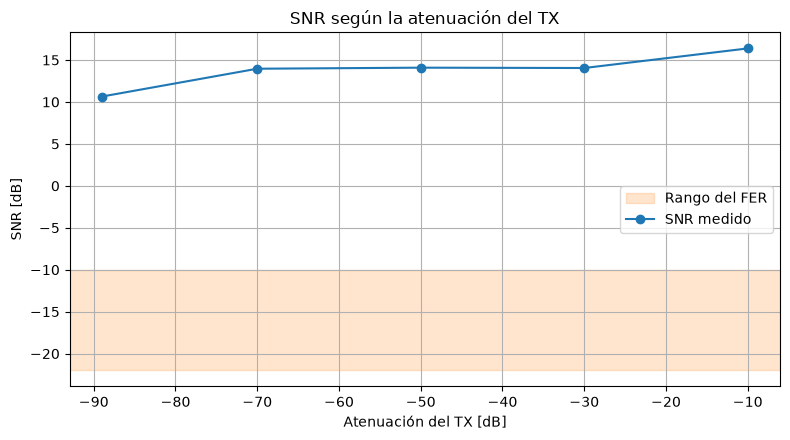

In [20]:
ATTENS_dB = np.array([-10.0, -30.0, -50.0, -70.0, -89.0])


def run_atten(pluto):
    runs = []
    for atten_dB in ATTENS_dB:
        sdr.set_tx_atten(pluto, atten_dB)
        runs.append(sdr.measure(pluto, p_sdr, 50, num_symbols, gap_range))
    return sdr.stack(runs, attens_dB=ATTENS_dB)


c_att, meta_att = sdr.acquire("captures/atten.npz", run_atten, p_sdr, URI)
evs_att = sdr.evaluate_all(c_att, meta_att, p_sdr, P_FA)
for atten_dB, gain, ev in zip(meta_att["attens_dB"], meta_att["gain"], evs_att):
    print(
        f"Atenuación {atten_dB:4.0f} dB: ganancia {gain:2.0f} dB, SNR {ev.snr:5.1f} dB, "
        f"FER {ev.errors.mean():.2f}"
    )
plots.snr_vs_atten(meta_att["attens_dB"], np.array([ev.snr for ev in evs_att]), FER_RANGE_dB);

**Observaciones**:
- El SNR queda entre 11 y 16 dB con cualquier atenuación del TX. Entre $-30$ y $-70$ dB casi no cambia ($\approx 14$ dB), porque el AGC sube la ganancia lo mismo que baja la señal y lo que limita el SNR es proporcional a la señal, como la distorsión del equipo, y no el ruido del receptor. Con $-89$ dB la ganancia llega a su máximo (73 dB) y el ruido del receptor empieza a pesar.
- El SNR nunca llega al rango donde cambia el FER, de $-22$ a $-10$ dB, porque con la atenuación máxima harían falta más de 20 dB de pérdida adicional. Como $-89$ dB es la máxima atenuación del TX, la señal se baja reduciendo la amplitud de las muestras (ver *FER por el aire*).
- Las 250 tramas se detectan con el inicio exacto, como en la simulación con SNR alto. Con SNR alto la cola de cada trama supera el umbral apenas termina, y el primer cruce puede llegar más de 8 símbolos antes del preámbulo siguiente, por eso el detector sigue el máximo después del cruce (ver *Detección en el tiempo: correlación con el preámbulo completo*).

### FER por el aire

Para medir el FER en el rango de la simulación, la señal tiene que llegar por debajo del ruido. Ese ruido tiene que ser el térmico del RX, que es gaussiano y es el que limita a un receptor real cuando la señal llega débil.

Con la máxima atenuación del TX la señal todavía llega por encima del ruido (ver *SNR y FER según la atenuación del TX*). Por eso se mantiene esa atenuación y además se multiplican las muestras por una escala de $-22$ a $-36$ dB antes de transmitirlas. La señal baja y el ruido del RX no cambia. La atenuación tiene que ser la máxima porque el TX también emite su propio ruido y la fuga de su oscilador local, que la escala no reduce y que tienen que llegar por debajo del ruido del RX.

Que la señal quede por debajo del ruido no es un problema para el ADC mientras el ruido ocupe varios niveles, porque entonces la cuantización agrega poco frente a él. Otra forma de llegar al rango del FER sería sumar ruido blanco gaussiano a las muestras antes de transmitirlas, con el mismo modelo que la simulación. No se usa porque ese ruido se genera en la PC y no es el que limita a un receptor real.

El FER medido se compara con el simulado en el canal plano, con el mismo detector y los mismos parámetros. Se espera que los puntos queden sobre la curva simulada, porque en el laboratorio las reflexiones recorren a lo sumo algunos metros más que el camino directo, unas decenas de ns, mucho menos que un chip de 1 µs, y el canal se comporta como plano. Si quedaran a la derecha (más SNR para el mismo FER), la diferencia sería una pérdida del equipo real. Con 200 tramas por punto, el menor FER que se puede medir es $1/200 = 5 \cdot 10^{-3}$. Un punto sin errores no entra en la escala logarítmica, y se dibuja en ese valor como cota superior.

In [21]:
# Escala digital del TX, con la máxima atenuación: lleva el SNR al rango del FER
SCALES_dB = np.arange(-36.0, -21.0, 2.0)


def run_thermal(pluto):
    sdr.set_tx_atten(pluto, sdr.TX_ATTEN_RANGE_DB[0])
    runs = [
        sdr.measure(pluto, p_sdr, N_FRAMES, num_symbols, gap_range, scale_dB=scale_dB)
        for scale_dB in SCALES_dB
    ]
    return sdr.stack(runs, scales_dB=SCALES_dB)


c_thermal, meta_thermal = sdr.acquire("captures/thermal.npz", run_thermal, p_sdr, URI)
evs_thermal = sdr.evaluate_all(c_thermal, meta_thermal, p_sdr, P_FA)
for scale_dB, gain, r, ev in zip(
    meta_thermal["scales_dB"], meta_thermal["gain"], c_thermal, evs_thermal
):
    print(
        f"Escala {scale_dB:5.1f} dB: SNR medido {ev.snr:5.1f} dB, ganancia {gain:2.0f} dB, "
        f"valor eficaz {np.sqrt(np.mean(np.abs(r) ** 2)):4.0f} niveles del ADC, "
        f"FER {ev.errors.mean():.3f} ({ev.errors.size - ev.timing.size} no detectadas)"
    )

timing = np.concatenate([ev.timing for ev in evs_thermal])
values, counts = np.unique(timing, return_counts=True)
print("Error del inicio detectado (muestras: tramas):", dict(zip(values.tolist(), counts.tolist())))

Escala -36.0 dB: SNR medido -22.7 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.925 (172 no detectadas)
Escala -34.0 dB: SNR medido -20.8 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.690 (89 no detectadas)
Escala -32.0 dB: SNR medido -17.7 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.185 (4 no detectadas)
Escala -30.0 dB: SNR medido -15.7 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.040 (0 no detectadas)
Escala -28.0 dB: SNR medido -13.7 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.020 (0 no detectadas)
Escala -26.0 dB: SNR medido -11.6 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.010 (0 no detectadas)
Escala -24.0 dB: SNR medido  -9.7 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.000 (0 no detectadas)
Escala -22.0 dB: SNR medido  -8.8 dB, ganancia 73 dB, valor eficaz   15 niveles del ADC, FER 0.000 (0 no detectadas)
Error del inicio detectado (muestras: tramas): {-640: 3, -512

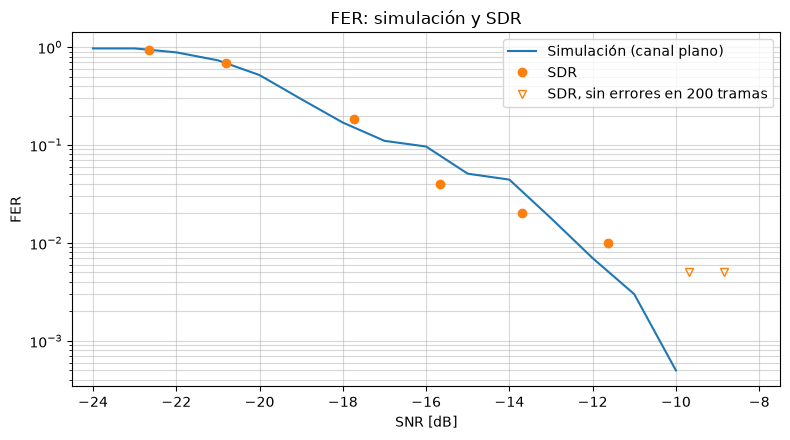

In [22]:
# Referencia: FER simulado en canal plano con el mismo detector y los mismos parámetros
SNRs_sim_dB = np.arange(-24.0, -7.0, 1.0)
fer_sim = simulation.fer_vs_snr(
    detection.detect_full,
    SNRs_sim_dB,
    channel.FLAT,
    p_sdr,
    P_FA,
    2000,
    num_symbols=num_symbols,
    gap=gap_range[0],
    min_errors=30,
)
plots.fer_sdr(
    SNRs_sim_dB,
    fer_sim,
    np.array([ev.snr for ev in evs_thermal]),
    np.array([ev.errors.mean() for ev in evs_thermal]),
    N_FRAMES,
);

**Observaciones**:
- El SNR medido baja lo mismo que la escala, de $\approx -23$ a $\approx -9$ dB, mientras la ganancia del RX queda en su máximo (73 dB) y el valor eficaz de la captura en 15 niveles del ADC en todos los puntos. El ruido no cambia con la señal, por lo que es el del RX, y ocupa decenas de niveles, así que la cuantización del ADC no pesa.
- El FER medido sigue la curva simulada en todo el rango, de $\approx 0.9$ a $-23$ dB a $0.01$ a $-12$ dB, con puntos a ambos lados de la curva. Las diferencias, como 0.04 contra $\approx 0.08$ cerca de $-16$ dB, son del orden de la dispersión de 200 tramas por punto, y desde $-10$ dB no se pierde ninguna trama. El ruido térmico del RX se comporta como el ruido blanco gaussiano de la simulación, y el equipo no agrega pérdidas al receptor.
- Las tramas no detectadas se concentran en $-23$ y $-21$ dB, y desde $-16$ dB se detectan todas. A partir de ese SNR las tramas perdidas son inicios corridos medio símbolo o un símbolo ($\pm 128$ y $\pm 256$ muestras, 101 de las 109 tramas corridas), por los picos laterales de $T[k]$, como en la simulación (ver *Frame Error Rate (FER)*).

## Anexo A: detección de una trama

### Falsas alarmas

En la detección del preámbulo, el detector declara $H_1$ en el primer cruce del umbral y toma como inicio el máximo del estadístico a partir de ese cruce. El silencio antes de la trama dura 5 símbolos, menos que el largo del preámbulo, así que una falsa alarma en el silencio queda corregida por el preámbulo que llega después y el FER casi no la muestra. Un receptor real, en cambio, pasa la mayor parte del tiempo escuchando solo ruido.

Para verificar que los umbrales de Neyman-Pearson cumplen la $P_{FA}$ pedida, se aplica cada método a 20000 símbolos de solo ruido y se mide la fracción de posiciones que superan el umbral. En el punto de operación la $P_{FA}$ por muestra de los métodos en el tiempo es $P_{FA}/2^{SF} \approx 1.3 \cdot 10^{-7}$, y harían falta del orden de $10^9$ muestras para observar suficientes falsas alarmas. Como la distribución bajo $H_0$ no depende del umbral, el cálculo se verifica en un rango medible, de $10^{-1}$ a $10^{-5}$ por posición. En frecuencia $V[m]$ es entero, y solo los umbrales $K = 1$ y $K = 2$ tienen una $P_{FA}$ medible, porque con $K = 3$ ($3.3 \cdot 10^{-6}$) se esperaría menos de una falsa alarma en 20000 ventanas.

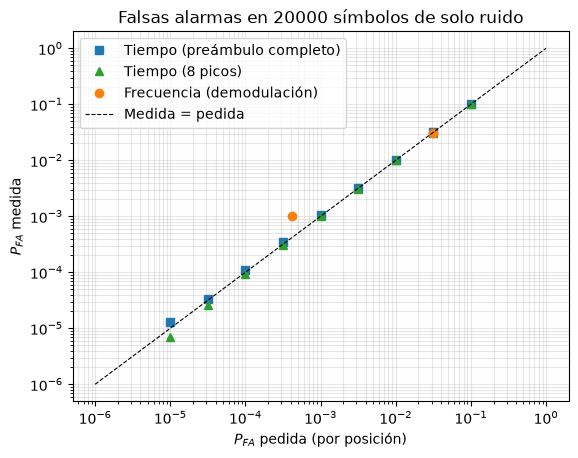

In [23]:
seed(0)  # El anexo no depende de la secuencia aleatoria de los capítulos anteriores
num_noise_symbols = 20000
P_FA_targets = np.logspace(-1, -5, 9)  # Por posición, para los métodos en el tiempo

false_alarms = simulation.measured_false_alarms(p, num_noise_symbols, P_FA_targets)
plots.false_alarms(false_alarms, num_noise_symbols);

**Observaciones**:
- Los métodos en el tiempo cumplen la $P_{FA}$ pedida, con menos de 10 % de diferencia hasta $10^{-4}$ por posición, y la demodulación del preámbulo la cumple con $K = 1$. Esto valida las distribuciones bajo $H_0$ (exponencial, Erlang y binomial) y respalda usar la $P_{FA}$ teórica en el punto de operación y en la ROC.
- En $10^{-5}$, y en frecuencia con $K = 2$, la medición se dispersa (entre 0.7 y 2.4 veces la pedida), porque se apoya en pocas falsas alarmas, $\approx 50$ y $\approx 8$ esperadas, que además llegan agrupadas. En el tiempo la plantilla se repite cada $2^{SF}/2$ muestras, así que una falsa alarma suele repetirse medio símbolo después, y en frecuencia cada ventana decidida como símbolo 0 cuenta en las 8 posiciones que la incluyen.

## Anexo B: prueba en el SDR

### Transmisión y recepción de las tramas

**Transmisión**: cada trama mide $F = 5184$ muestras, el preámbulo de 10.25 símbolos y 10 símbolos de *payload*, y la precede un silencio de 5 a 10 símbolos (1280 a 2560 muestras) sin redondear a símbolos enteros. El TX repite sin pausa un buffer de 50 o 200 tramas, de largo par, porque con un largo impar el TX del Pluto agrega una muestra en cada repetición y las tramas siguientes llegan corridas. El RX entrega las muestras en bloques que pasan por una cola, así que después de cambiar la señal transmitida se descartan los primeros bloques, que todavía tienen la señal anterior.

**Largo de la captura**: la captura empieza en un punto cualquiera del buffer, porque depende de la demora de la red y del equipo. Por eso tiene el largo del buffer más el de tres tramas con el silencio más largo. Las dos primeras dan lugar a que el receptor encuentre un silencio y el primer preámbulo, y las tramas que empiezan ahí no se cuentan. Después hay un buffer completo, en el que cada trama empieza exactamente una vez, y la tercera deja lugar para que la última termine dentro de la captura.

**Receptor**: recorre la captura con una ventana de $2F$ muestras, como si las muestras le llegaran de a poco. La primera ventana empieza en el símbolo de menor energía, que con SNR alto cae en un silencio, porque si empezara en la mitad de un *payload* podría confundir sus *chirps* con los del preámbulo. En cada ventana busca un preámbulo con el detector. Si lo encuentra, guarda el inicio y la ventana siguiente empieza donde termina esa trama, y si no, la ventana avanza $F$ muestras. Así cada trama entra entera en alguna ventana, porque una trama que empieza en las primeras $F$ muestras de una ventana termina dentro de ella, y una que empieza en las últimas $F$ queda en las primeras $F$ de la ventana siguiente.

### Fondo de escala del ADC

El ADC del Pluto representa cada muestra de I y de Q con 12 bits, entre $-2048$ y $2047$. El mayor valor es el fondo de escala, y los niveles se expresan en dB respecto de él. El ruido de cuantización tiene una potencia fija, así que la relación señal-ruido de cuantización (SQNR) depende del nivel de la señal. Con un tono que llega justo al fondo de escala, un ADC de $N$ bits tiene

$$
SQNR \approx 6.02\,N + 1.76 \text{ dB} \approx 74 \text{ dB} \quad (N = 12)
$$

y cada dB que la señal queda por debajo del fondo de escala es un dB menos de SQNR. Si la señal supera el fondo de escala, el ADC la recorta.

La ganancia del RX la elige el AGC en el modo *slow attack*, pensado para señales continuas como la del TX cíclico, que corrige la ganancia de a poco según la potencia promedio. El AGC no lleva el pico de la señal al fondo de escala, sino que deja un margen para los picos. Con SNR negativo la señal recibida es casi toda ruido gaussiano, con picos de varias veces su desvío estándar.

Para ver cuánto del rango usa la señal se transmite un tono, una exponencial compleja de $\approx 125$ kHz, cuyo pico coincide con su valor eficaz porque su amplitud es constante. Se captura con la ganancia que eligió el AGC, con 20 dB menos y con 16 dB más. Se espera:
- **Con la ganancia del AGC**: un círculo en el plano I/Q. Una elipse indicaría que I y Q tienen distinta ganancia o no están exactamente a 90°. En el espectro aparecen el tono, su imagen en $-125$ kHz, causada por ese mismo desbalance, y la fuga del oscilador local en 0 Hz.
- **Con 20 dB menos**: el tono usa menos niveles del ADC. Si el ruido fuera solo el de cuantización, que no depende de la ganancia, el SNR bajaría lo mismo que la ganancia.
- **Con 16 dB más**: I y Q se recortan, el círculo se vuelve un cuadrado y aparecen armónicos del tono.

Ganancia  9 dB: nivel -11.7 dB respecto del fondo de escala, pico  26%, SNR del tono  51 dB
Ganancia  0 dB: nivel -20.8 dB respecto del fondo de escala, pico   9%, SNR del tono  47 dB
Ganancia 25 dB: nivel   1.2 dB respecto del fondo de escala, pico 100%, SNR del tono  15 dB


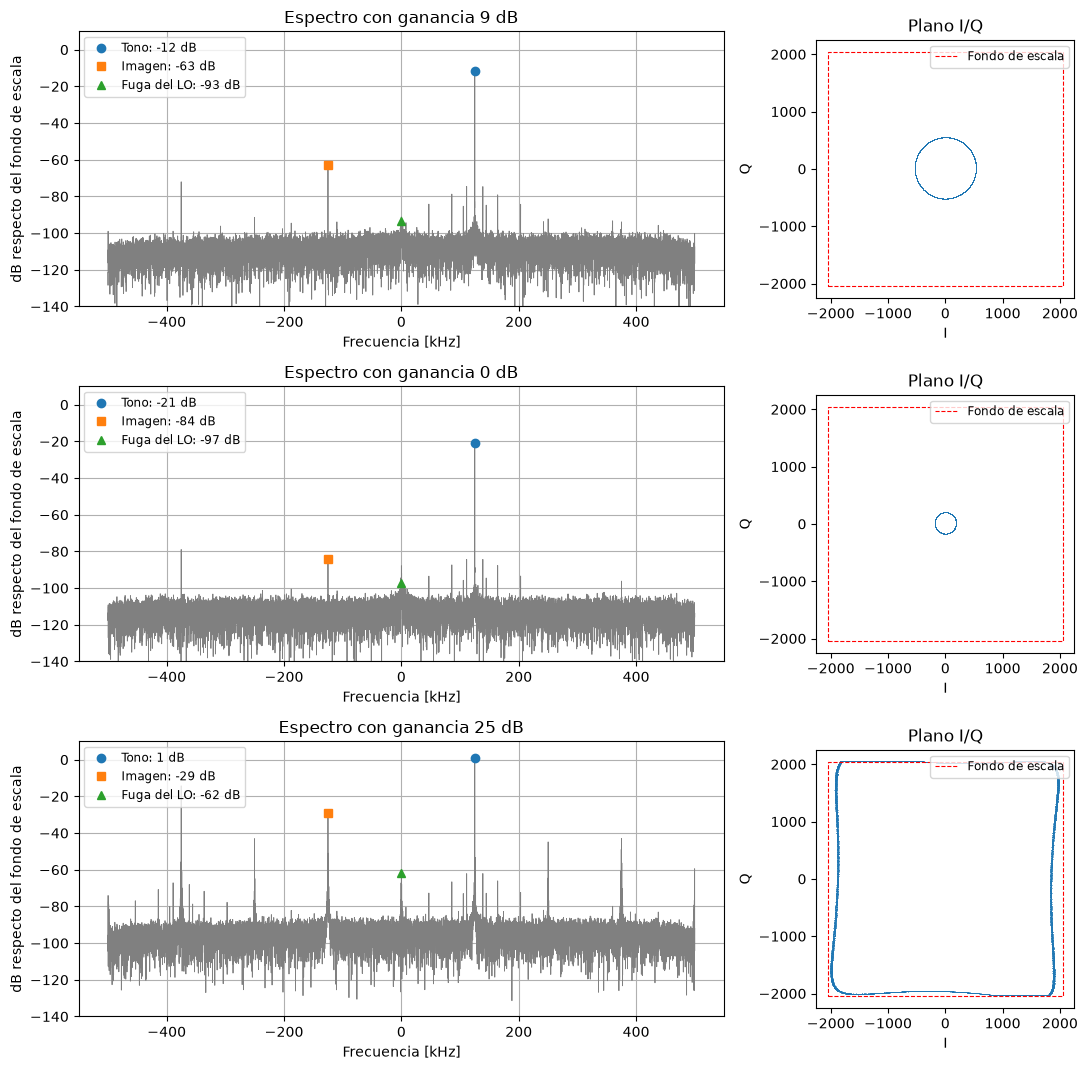

In [24]:
# Tono de ~125 kHz con un número entero de ciclos en el buffer, para que el TX cíclico no tenga
# saltos. K_TONE impar: el error de cuantización no se repite cada pocas muestras
N_TONE, K_TONE = 2**14, 2**11 + 1
GAIN_OFFSETS_dB = np.array([0, -20, 16])  # Respecto de la ganancia del AGC
tone = np.exp(2j * np.pi * K_TONE * np.arange(N_TONE) / N_TONE)


def run_tone(pluto):
    _, agc_gain = sdr.record(pluto, tone, N_TONE)  # El AGC elige la ganancia
    gains = np.clip(agc_gain + GAIN_OFFSETS_dB, 0, 70)  # Rango de ganancia del RX
    captures = []
    for gain in gains:
        pluto.rx_hardwaregain_chan0 = float(gain)
        captures.append(sdr.record(pluto, tone, N_TONE, calibrate=False)[0])
    return np.array(captures), {"gains_dB": gains}


c_tone, meta_tone = sdr.acquire("captures/tone.npz", run_tone, p_sdr, URI)
for r, gain in zip(c_tone, meta_tone["gains_dB"]):
    P = np.abs(np.fft.fft(r)) ** 2  # Tono en K_TONE, imagen en -K_TONE y fuga del LO en 0
    snr_tone_dB = 10 * np.log10(P[K_TONE] / (P.sum() - P[K_TONE] - P[-K_TONE] - P[0]))
    level_dB = 10 * np.log10(metrics.power(r) / sdr.ADC_FULL_SCALE**2)
    print(
        f"Ganancia {gain:2.0f} dB: nivel {level_dB:5.1f} dB respecto del fondo de escala, "
        f"pico {sdr.adc_peak(r) / sdr.ADC_FULL_SCALE:4.0%}, SNR del tono {snr_tone_dB:3.0f} dB"
    )
plots.sdr_tone(c_tone, meta_tone["gains_dB"], K_TONE, p_sdr);

**Observaciones**:
- Con la ganancia del AGC (9 dB) el tono queda a $-11.7$ dB del fondo de escala, con el pico en el 26 % del rango. El AGC deja $\approx 12$ dB de margen para los picos.
- El plano I/Q es un círculo. La imagen queda 65 dB debajo del tono y la fuga del oscilador local, 76 dB debajo, así que el desbalance entre I y Q y la fuga no afectan al receptor.
- El SNR del tono es de 52 dB, menos que los $\approx 62$ dB de SQNR que corresponden a ese nivel ($74 - 11.7$). La captura con menos ganancia quedó en el mínimo del RX, 0 dB, 9 dB menos que el AGC, y su SNR bajó solo 5 dB. El ruido que domina no es el de cuantización sino el analógico del RX, que la ganancia amplifica junto con el tono.
- Con 16 dB más (25 dB) I y Q se recortan, el círculo se vuelve un cuadrado, aparecen armónicos del tono (el mayor en $-375$ kHz) y la imagen sube a $-26$ dB. El SNR cae a 15 dB.